# 01 — Data Cleaning
**Week 2, Steps 1–6**

Loads all 12 raw CSVs, applies the `DataCleaner` pipeline, shows before/after
profiles for each table, and displays the cleaning log.

> Run **Restart & Run All** to reproduce from scratch.


In [1]:
# Run from the project root (works from notebooks/ too)
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
print("Working directory:", Path.cwd())

Working directory: /Users/cloudanix/Sahil/Sakshi/Project/Zomato_Business_Intelligence


In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (10, 4)

from src.ingest import load_all
from src.clean import CleaningLog, DataCleaner, CITY_ALIASES, iqr_bounds

rng = np.random.default_rng(42)  # seeded RNG for any sampling (PRD requirement)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.2f}'.format)

RAW_DIR   = Path('data/raw')
CLEAN_DIR = Path('data/cleaned')
print("Libraries loaded ✅")


Libraries loaded ✅


## 1. Load raw CSVs

In [3]:
raw = load_all()
print(f"Tables loaded: {len(raw)}")
summary = pd.DataFrame([
    {"table": name, "rows": len(df), "cols": len(df.columns)}
    for name, df in sorted(raw.items())
])
summary


Tables loaded: 12


,table,rows,cols
0,cities,25,5
1,customer_feedback,14200,7
2,customers,12180,13
3,delivery_partners,2000,10
4,menu,8997,8
5,order_items,42378,6
6,orders,20705,15
7,payments,20493,6
8,promotions,300,6
9,restaurants,1200,13


## 2. Run cleaning pipeline

In [4]:
cities_list = raw['cities']['city'].dropna().str.strip().tolist()
log = CleaningLog()
cleaner = DataCleaner(cities_list, CITY_ALIASES, log)
cleaned = cleaner.clean_all(raw)
print(f"Cleaning complete. Log entries: {len(log.rows)}")


Cleaning complete. Log entries: 28


## 3. Before / After row counts

In [5]:
comparison = pd.DataFrame([
    {"table": t, "raw_rows": len(raw[t]), "cleaned_rows": len(cleaned[t]),
     "removed": len(raw[t]) - len(cleaned[t])}
    for t in sorted(cleaned)
])
comparison["removal_%"] = (comparison["removed"] / comparison["raw_rows"] * 100).round(2)
comparison


,table,raw_rows,cleaned_rows,removed,removal_%
0,cities,25,25,0,0.00
1,customer_feedback,14200,14180,20,0.14
2,customers,12180,12000,180,1.48
3,delivery_partners,2000,2000,0,0.00
4,menu,8997,8997,0,0.00
5,order_items,42378,42361,17,0.04
6,orders,20705,20475,230,1.11
7,payments,20493,20469,24,0.12
8,promotions,300,300,0,0.00
9,restaurants,1200,1200,0,0.00


## 4. Cleaning log

In [6]:
log_df = pd.DataFrame(log.rows)
log_df.sort_values(["table","rows_affected"], ascending=[True, False])


,table,step,rows_affected,note
0,cities,average_income: null values,2,
23,customer_feedback,has_review flag added,13142,
22,customer_feedback,delivery_rating: out of range -> NaN,129,
27,customer_feedback,quarantine orphan order_id,20,parent order was quarantined — saved to quaran...
4,customers,phone: invalid -> NaN,7529,
2,customers,city standardized,904,
1,customers,age: impossible values -> NaN,429,outside 15-90 range
6,customers,pincode: invalid -> NaN,404,
5,customers,email: invalid -> NaN,332,
7,customers,drop duplicate customer_id,180,exact copies — keep first occurrence


## 5. City canonical check

In [7]:
city_tables = ['customers', 'restaurants', 'delivery_partners', 'weather', 'traffic']
for tbl in city_tables:
    unknown = set(cleaned[tbl]['city'].dropna()) - set(cities_list)
    status = "✅ all canonical" if not unknown else f"❌ {sorted(unknown)}"
    print(f"{tbl:<22} {status}")


customers              ✅ all canonical
restaurants            ✅ all canonical
delivery_partners      ✅ all canonical
weather                ✅ all canonical
traffic                ✅ all canonical


## 6. Category values match SQL

In [8]:
checks = {
    "orders.order_status":               ["Cancelled","Delivered","Delivered Late","Food Not Delivered"],
    "orders.payment_method":             ["Cash On Delivery","Credit Card","Debit Card","Net Banking","Upi","Wallet"],
    "customers.membership":              ["Basic","Gold","Zomato Pro"],
    "customers.gender":                  ["Female","Male","Other"],
    "customer_feedback.sentiment":       ["Negative","Neutral","Positive"],
    "delivery_partners.vehicle_type":    ["Bicycle","Bike","Car","Scooter"],
    "payments.payment_status":           ["Failed","Pending","Refunded","Success"],
    "menu.availability":                 ["No","Yes"],
}
for col_path, expected in checks.items():
    tbl, col = col_path.split(".")
    actual = sorted(cleaned[tbl][col].dropna().unique().tolist())
    ok = actual == expected
    print(f"{'✅' if ok else '❌'} {col_path}: {actual}")


✅ orders.order_status: ['Cancelled', 'Delivered', 'Delivered Late', 'Food Not Delivered']
✅ orders.payment_method: ['Cash On Delivery', 'Credit Card', 'Debit Card', 'Net Banking', 'Upi', 'Wallet']
✅ customers.membership: ['Basic', 'Gold', 'Zomato Pro']
✅ customers.gender: ['Female', 'Male', 'Other']
✅ customer_feedback.sentiment: ['Negative', 'Neutral', 'Positive']
✅ delivery_partners.vehicle_type: ['Bicycle', 'Bike', 'Car', 'Scooter']
✅ payments.payment_status: ['Failed', 'Pending', 'Refunded', 'Success']
✅ menu.availability: ['No', 'Yes']


## 7. Missing value strategies

In [9]:
strategies = {
    "customers.age":                 "Impossible → NaN, filled with membership median, age_was_missing flag",
    "delivery_partners.age":         "Impossible → NaN, filled with overall median, age_was_missing flag",
    "restaurants.rating":            "Out-of-range → NaN, filled with city median",
    "delivery_partners.rating":      "Out-of-range → NaN, filled with city median",
    "customer_feedback.*_rating":    "LEFT MISSING — missing = didn't rate",
    "customers.phone":               "Invalid → NaN, 133 repaired, phone_valid flag",
    "customers.email":               "Invalid → NaN, email_valid flag",
    "customers.pincode":             "Invalid → NaN, pincode_valid flag",
    "customer_feedback.review":      "LEFT MISSING, has_review flag added",
    "orders.delivery_time_minutes":  "NOT IMPUTED — prediction target; <=0 → NaN",
    "orders.delivery_fee=0":         "KEPT — may be legitimate free delivery",
}
for col, strategy in strategies.items():
    print(f"  {col:<40} {strategy}")


  customers.age                            Impossible → NaN, filled with membership median, age_was_missing flag
  delivery_partners.age                    Impossible → NaN, filled with overall median, age_was_missing flag
  restaurants.rating                       Out-of-range → NaN, filled with city median
  delivery_partners.rating                 Out-of-range → NaN, filled with city median
  customer_feedback.*_rating               LEFT MISSING — missing = didn't rate
  customers.phone                          Invalid → NaN, 133 repaired, phone_valid flag
  customers.email                          Invalid → NaN, email_valid flag
  customers.pincode                        Invalid → NaN, pincode_valid flag
  customer_feedback.review                 LEFT MISSING, has_review flag added
  orders.delivery_time_minutes             NOT IMPUTED — prediction target; <=0 → NaN
  orders.delivery_fee=0                    KEPT — may be legitimate free delivery


## 8. Outlier analysis — delivery_time_minutes

Delivery time percentiles (valid orders, >0):
percentile  minutes
       p50    35.00
       p75    43.00
       p90    55.00
       p95    67.00
       p99    89.00
     p99.9   370.40

IQR bounds (k=3.0): [-17.0, 88.0]
Flagged outliers: 211
Bounds decision: use dt_outlier_flag column; Week 3 decides exclusion threshold


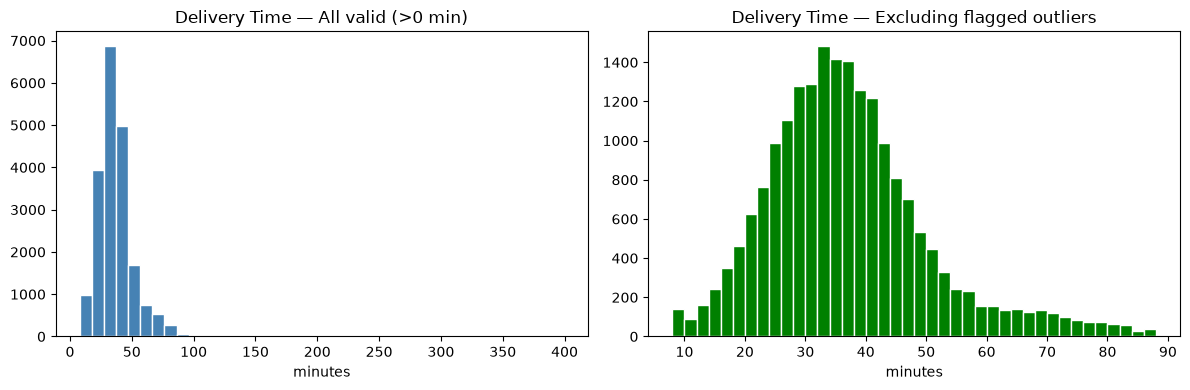

Plot saved → reports/delivery_time_outliers.png


In [10]:
dt = cleaned['orders']['delivery_time_minutes'].dropna()

# Percentile table
pcts = np.percentile(dt, [50, 75, 90, 95, 99, 99.9])
pct_df = pd.DataFrame({
    'percentile': ['p50','p75','p90','p95','p99','p99.9'],
    'minutes': pcts.round(1)
})
print("Delivery time percentiles (valid orders, >0):")
print(pct_df.to_string(index=False))

low, high = iqr_bounds(dt, k=3.0)
print(f"\nIQR bounds (k=3.0): [{low:.1f}, {high:.1f}]")
print(f"Flagged outliers: {((dt < low) | (dt > high)).sum()}")
print(f"Bounds decision: use dt_outlier_flag column; Week 3 decides exclusion threshold")

# Before/After histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(cleaned['orders']['delivery_time_minutes'].dropna(), bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Delivery Time — All valid (>0 min)')
axes[0].set_xlabel('minutes')
axes[1].hist(dt[dt.between(low, high)], bins=40, color='green', edgecolor='white')
axes[1].set_title('Delivery Time — Excluding flagged outliers')
axes[1].set_xlabel('minutes')
plt.tight_layout()
plt.savefig('reports/delivery_time_outliers.png', dpi=100, bbox_inches='tight')
plt.show()
print("Plot saved → reports/delivery_time_outliers.png")


## 9. Cross-tab: delivery time null vs order status

In [11]:
ct = pd.crosstab(
    cleaned['orders']['order_status'],
    cleaned['orders']['delivery_time_minutes'].isna().map({True:'null',False:'has value'}),
    margins=True
)
print("Finding: most null delivery times are on non-Delivered orders (expected):")
ct


Finding: most null delivery times are on non-Delivered orders (expected):


delivery_time_minutes,has value,null,All
order_status,,,
Cancelled,4525,44,4569
Delivered,11273,117,11390
Delivered Late,2135,19,2154
Food Not Delivered,2335,27,2362
All,20268,207,20475


## 10. Cleaning log summary by table

In [12]:
log_df = pd.DataFrame(log.rows)
pivot = log_df.pivot_table(
    index='table', columns='step', values='rows_affected',
    aggfunc='sum', fill_value=0
)
pivot


step,age: impossible values -> NaN,average_delivery_time: <=0 -> NaN,average_income: null values,city standardized,delivery_rating: out of range -> NaN,delivery_time nulls mostly on non-delivered orders,delivery_time_minutes: <=0 -> NaN,delivery_time_minutes: outlier flag (IQR k=3.0),drop blank city rows,drop duplicate customer_id,...,food_cost: <=0 -> NaN,has_review flag added,order_date: ambiguous '/' date read as MM/DD,phone: invalid -> NaN,phone: repaired (stripped +91/0 prefix),pincode: invalid -> NaN,quarantine orphan order_id,quarantine orphan orders,rating: filled with city median,rating: out of range (>5) -> NaN
table,,,,,,,,,,,,,,,,,,,,,
cities,0,0,2,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
customer_feedback,0,0,0,0,129,0,0,0,0,0,...,0,13142,0,0,0,0,20,0,0,0
customers,429,0,0,904,0,0,0,0,0,180,...,0,0,0,7529,133,404,0,0,0,0
delivery_partners,0,27,0,128,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,34,0
order_items,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,17,0,0,0
orders,0,0,0,0,0,208,209,211,0,0,...,182,0,3222,0,0,0,0,25,0,0
payments,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,24,0,0,0
restaurants,0,0,0,83,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,40,18
weather,0,0,0,0,0,0,0,0,91,0,...,0,0,0,0,0,0,0,0,0,0
